# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
|Raihan Nurhakim| 5054251030 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [ ]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [47]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.columns = df.columns.str.strip()

print("shape:", df.shape)
print("\ntipe data:")
print(df.dtypes.value_counts())
print("\nmissing values per kolom:", df.isnull().sum().sum())
print("\nstatistik deskriptif:")
df.describe()

shape: (7043, 21)

tipe data:
object     18
int64       2
float64     1
Name: count, dtype: int64

missing values per kolom: 0

statistik deskriptif:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Distribusi kelas:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Rasio kelas minoritas: 26.54%


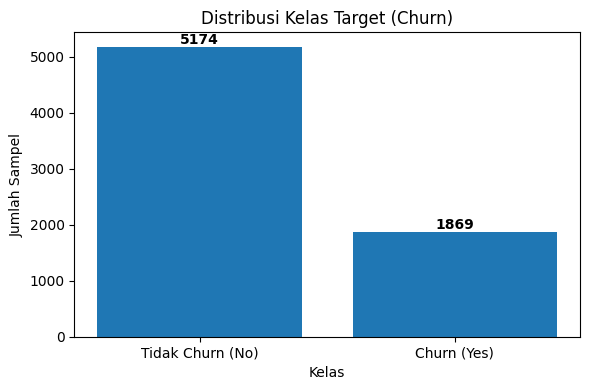

In [ ]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
class_counts = df["Churn"].value_counts()

print("Distribusi kelas:")
print(class_counts)

minority_ratio = class_counts.min() / len(df) * 100
print(f"\nRasio kelas minoritas: {minority_ratio:.2f}%")

plt.figure(figsize=(6, 4))

bars = plt.bar(["Tidak Churn (No)", "Churn (Yes)"], [class_counts["No"], class_counts["Yes"]])

plt.title("Distribusi Kelas Target (Churn)")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Sampel")

for bar in bars:
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi,
        str(int(tinggi)),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

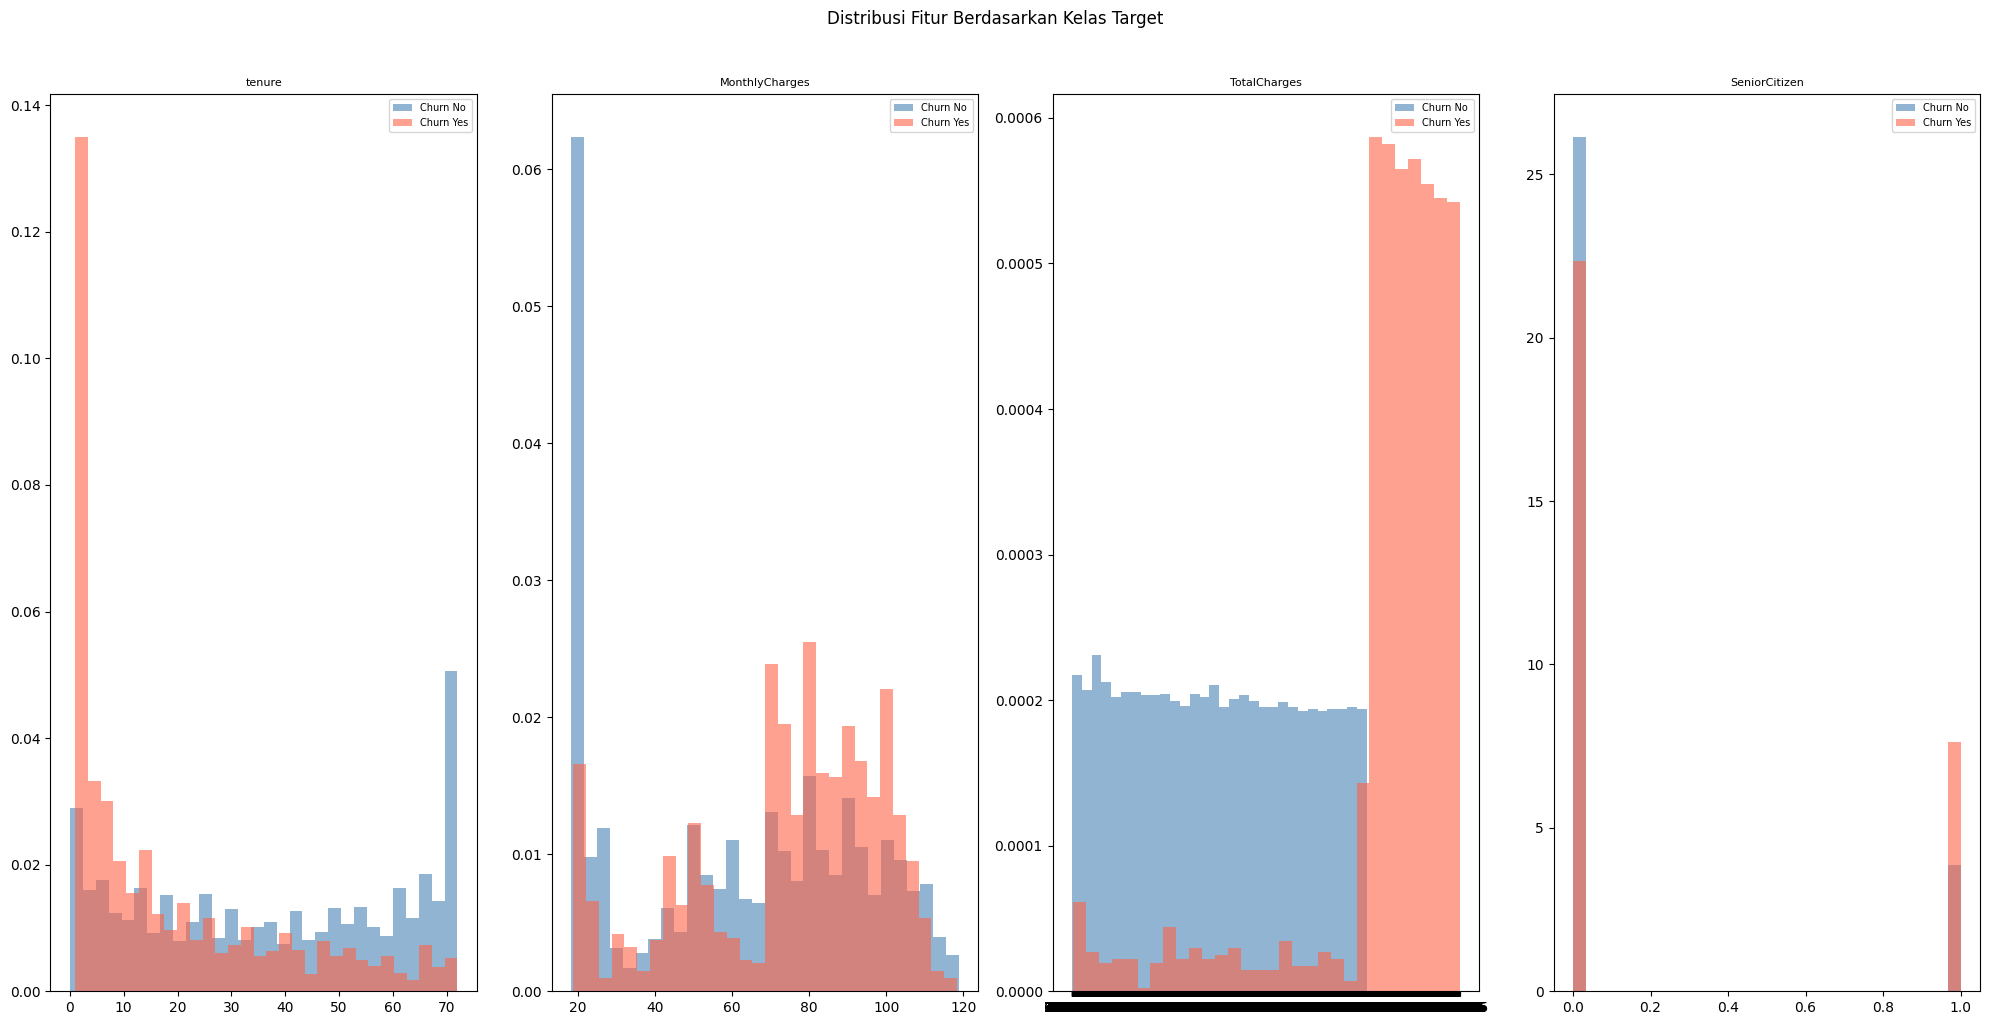

In [49]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
top_features = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]

fig, axes = plt.subplots(1, 4, figsize=(20, 10))
for i, feat in enumerate(top_features):
    for cls, color in [("No", "steelblue"), ("Yes", "tomato")]:
        axes[i].hist(df[df["Churn"]==cls][feat], bins=30, alpha=0.6,
                     label=f"Churn {cls}", color=color, density=True)
    axes[i].set_title(feat[:25], fontsize=8)
    axes[i].legend(fontsize=7)
plt.suptitle("Distribusi Fitur Berdasarkan Kelas Target", y=1.02)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [ ]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)


In [ ]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn", "customerID"])
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [52]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [ ]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [ ]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).
mlp = MLPClassifier(hidden_layer_sizes=(10,), activation="relu", max_iter=500, random_state=42)

mlp.fit(X_train_scaled, y_train)

MLPClassifier(hidden_layer_sizes=(10,), max_iter=500, random_state=42)

In [ ]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred = mlp.predict(X_test_scaled)
print("Hasil prediksi:")
print(y_pred[:10])

Hasil prediksi:
[0 1 0 0 0 1 1 0 0 0]


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [ ]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.
activations = ["relu", "tanh", "logistic"]
activation_models = {}

for activation in activations:
    model = MLPClassifier(hidden_layer_sizes=(10,), activation=activation, max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    activation_models[activation] = model

In [ ]:
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.
activation_results = []

for activation, model in activation_models.items():
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    activation_results.append({"Activation": activation,"Accuracy": accuracy})

activation_df = pd.DataFrame(activation_results)
print(activation_df)

  Activation  Accuracy
0       relu  0.787793
1       tanh  0.793471
2   logistic  0.792761


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [ ]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.
best_activation = activation_df.loc[activation_df["Accuracy"].idxmax(), "Activation"]

architectures = [(2,), (5,), (10,), (50,), (100, 50)]

architecture_models = {}

for architecture in architectures:
    model = MLPClassifier(hidden_layer_sizes=architecture, activation=best_activation, max_iter=500, random_state=42)

    model.fit(X_train_scaled, y_train)
    architecture_models[architecture] = model

c:\Users\Raihan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [59]:
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
architecture_results = []

for architecture, model in architecture_models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    architecture_results.append({
        "Architecture": str(architecture),
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

architecture_df = pd.DataFrame(architecture_results)
print(architecture_df)

  Architecture  Train Accuracy  Test Accuracy
0         (2,)        0.805999       0.794890
1         (5,)        0.810969       0.790632
2        (10,)        0.824636       0.793471
3        (50,)        0.895989       0.751597
4    (100, 50)        0.959176       0.754436


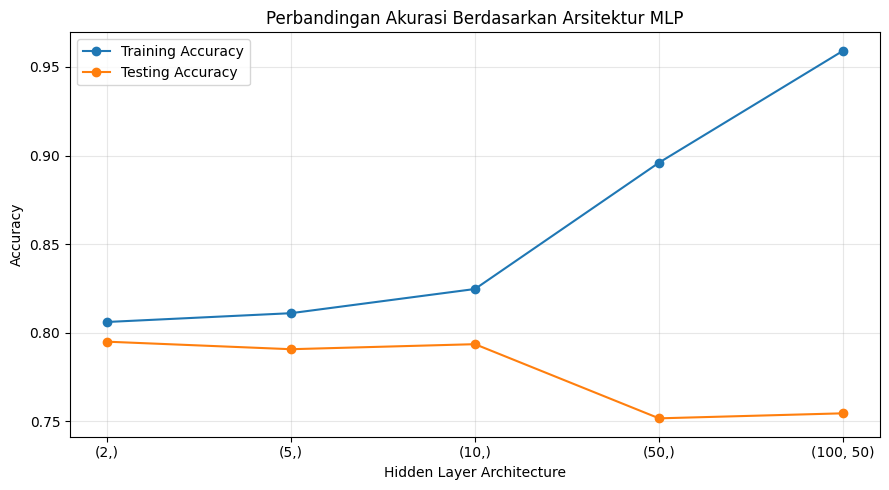

In [ ]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
plt.figure(figsize=(9, 5))

plt.plot(
    architecture_df["Architecture"],
    architecture_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    architecture_df["Architecture"],
    architecture_df["Test Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.title("Perbandingan Akurasi Berdasarkan Arsitektur MLP")
plt.xlabel("Hidden Layer Architecture")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Evaluasi Model

In [ ]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
best_activation_model = activation_models[best_activation]

best_architecture = architecture_df.loc[
    architecture_df["Test Accuracy"].idxmax(), "Architecture"
]

best_architecture = eval(best_architecture)
best_architecture_model = architecture_models[best_architecture]

models_to_evaluate = {
    "Best Activation": best_activation_model,
    "Best Architecture": best_architecture_model
}

evaluation_results = []

for name, model in models_to_evaluate.items():
    y_pred = model.predict(X_test_scaled)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation_results)
print(evaluation_df)

               Model  Accuracy  Precision    Recall  F1-Score
0    Best Activation  0.793471   0.630094  0.537433  0.580087
1  Best Architecture  0.794890   0.632399  0.542781  0.584173


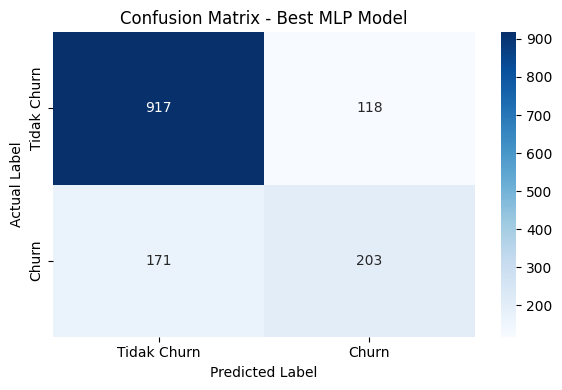

In [62]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.
y_pred = best_architecture_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Tidak Churn", "Churn"],
    yticklabels=["Tidak Churn", "Churn"]
)

plt.title("Confusion Matrix - Best MLP Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

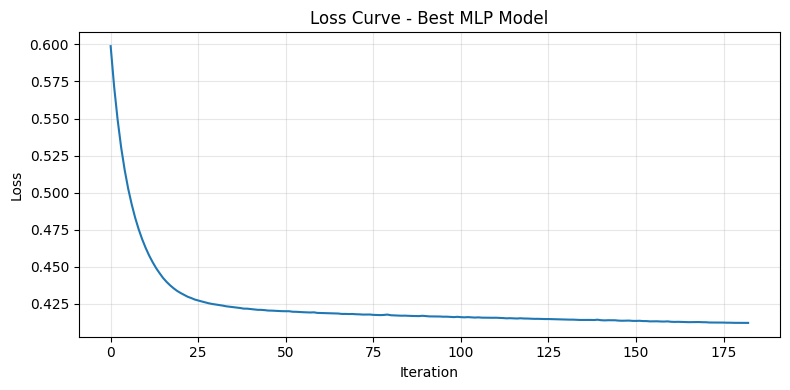

In [63]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.
plt.figure(figsize=(8, 4))

plt.plot(best_architecture_model.loss_curve_)

plt.title("Loss Curve - Best MLP Model")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

Berdasarkan eksperimen yang telah dilakukan, terdapat beberapa hal yang dapat dianalisis dari penerapan Artificial Neural Network (ANN) menggunakan MLPClassifier untuk memprediksi customer churn.

**1. Pengaruh Fungsi Aktivasi terhadap Performa Model**

Berdasarkan hasil pengujian, fungsi aktivasi tanh memperoleh akurasi tertinggi sebesar 79,35%, diikuti logistic sebesar 79,28%, dan relu sebesar 78,78%. Perbedaan akurasi ketiganya relatif kecil. Hal ini menunjukkan bahwa pemilihan fungsi aktivasi memberikan pengaruh terhadap performa model, meskipun tidak terlalu signifikan pada eksperimen ini. Fungsi aktivasi tanh kemudian dipilih untuk eksperimen selanjutnya karena menghasilkan akurasi tertinggi.

**2. Pengaruh Ukuran Arsitektur terhadap Overfitting**

Hasil eksperimen menunjukkan bahwa semakin besar arsitektur jaringan, akurasi training cenderung meningkat. Namun, peningkatan tersebut tidak diikuti oleh peningkatan akurasi testing. Arsitektur (50,) memperoleh akurasi training sebesar 89,60% dan testing sebesar 75,16%, sedangkan arsitektur (100, 50) memperoleh akurasi training sebesar 95,92% dan testing sebesar 75,44%.

Sebaliknya, arsitektur yang lebih sederhana seperti (2,), (5,), dan (10,) memiliki selisih akurasi training dan testing yang lebih kecil. Hal ini menunjukkan adanya indikasi overfitting pada arsitektur yang lebih besar, karena model semakin baik dalam mempelajari data training tetapi kurang mampu melakukan generalisasi terhadap data baru.

**3. Evaluasi Performa Model Terbaik**

Berdasarkan hasil evaluasi, model dengan arsitektur (2,) menghasilkan performa terbaik pada data testing dengan akurasi sebesar 79,49%, precision sebesar 63,24%, recall sebesar 54,28%, dan F1-score sebesar 58,42%.

Nilai precision menunjukkan bahwa prediksi churn yang dihasilkan model memiliki ketepatan sebesar 63,24%. Sementara itu, recall sebesar 54,28% menunjukkan bahwa model masih belum berhasil mendeteksi seluruh pelanggan yang benar-benar melakukan churn. Hal ini menjadi perhatian karena kemampuan mendeteksi pelanggan yang berpotensi berhenti berlangganan merupakan tujuan utama dari klasifikasi ini.

**4. Analisis Loss Curve**

Berdasarkan loss curve, perubahan nilai loss dapat digunakan untuk mengamati proses pembelajaran model pada setiap iterasi. Penurunan loss menunjukkan bahwa model sedang mempelajari pola dari data training. Namun, model terbaik masih perlu diperhatikan dari sisi konvergensi, terutama karena pada eksperimen arsitektur terdapat peringatan bahwa salah satu model belum mencapai konvergensi hingga batas 500 iterasi.

Secara keseluruhan, hasil eksperimen menunjukkan bahwa arsitektur yang lebih besar tidak selalu menghasilkan performa yang lebih baik. Model dengan arsitektur sederhana justru memberikan hasil testing yang lebih baik dan memiliki indikasi overfitting yang lebih rendah.


# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan

Berdasarkan eksperimen yang telah dilakukan, dapat disimpulkan bahwa Artificial Neural Network (ANN) dengan MLPClassifier dapat digunakan untuk melakukan klasifikasi customer churn pada dataset Telco Customer Churn.

Hasil eksperimen menunjukkan bahwa fungsi aktivasi tanh menghasilkan akurasi tertinggi sebesar 79,35% dibandingkan relu dan logistic. Sementara itu, pada pengujian variasi arsitektur, model dengan hidden layer (2,) menghasilkan akurasi testing tertinggi sebesar 79,49%, dengan precision 63,24%, recall 54,28%, dan F1-score 58,42%.

Selain itu, penggunaan arsitektur yang lebih besar tidak selalu meningkatkan performa model. Peningkatan akurasi training yang tidak diikuti peningkatan akurasi testing menunjukkan adanya indikasi overfitting. Oleh karena itu, pemilihan arsitektur perlu mempertimbangkan kemampuan model dalam melakukan generalisasi terhadap data baru, bukan hanya performa pada data training.

### Saran

Untuk pengembangan eksperimen selanjutnya, terdapat beberapa hal yang dapat dilakukan:

1. Mencoba variasi hyperparameter lainnya, seperti learning rate, solver, dan jumlah iterasi untuk memperoleh performa model yang lebih optimal.
2. Menerapkan teknik penanganan data imbalanced, seperti oversampling atau class weighting, agar model dapat mendeteksi pelanggan yang melakukan churn dengan lebih baik.
3. Melakukan tuning arsitektur dan regularisasi, misalnya dengan menambahkan parameter alpha atau mencoba early stopping untuk mengurangi risiko overfitting.
4. Menggunakan cross-validation agar evaluasi performa model menjadi lebih konsisten dan tidak hanya bergantung pada satu pembagian data training dan testing.
